In [1]:

print("Language Learning Prediction Project")
print("Jupyter Notebook is working!")


Language Learning Prediction Project
Jupyter Notebook is working!


In [2]:

import sys

print("Python version:", sys.version)
print("Python executable:", sys.executable)


Python version: 3.13.9 | packaged by Anaconda, Inc. | (main, Oct 21 2025, 19:09:58) [MSC v.1929 64 bit (AMD64)]
Python executable: c:\Users\pdhav\anaconda3\python.exe


In [3]:

import pandas as pd
import numpy as np
import matplotlib
import sklearn

print("pandas:", pd.__version__)
print("NumPy:", np.__version__)
print("Matplotlib:", matplotlib.__version__)
print("scikit-learn:", sklearn.__version__)


pandas: 2.2.3
NumPy: 2.1.3
Matplotlib: 3.10.0
scikit-learn: 1.6.1


In [4]:

import pandas as pd

data_path = "../data/raw/"

df = pd.read_csv(data_path + "language_learning_fluency.csv")
data_dictionary = pd.read_csv(data_path + "data_dictionary_language.csv")

print("Dataset loaded successfully!")



Dataset loaded successfully!


In [5]:

print("Main dataset shape:", df.shape)
print("Data dictionary shape:", data_dictionary.shape)



Main dataset shape: (45000, 18)
Data dictionary shape: (18, 3)


In [9]:

data_dictionary.head(18)


,column,type,description
0,learner_id,string,Unique learner id
1,fsi_category,int,Target-language difficulty (FSI 1=easy like Sp...
2,related_language,int,1 if the learner knows a language related to t...
3,prior_languages,int,Number of languages already known
4,age_started,int,Age when the learner started (affects accent c...
5,total_study_hours,int,Total study hours (the biggest single lever)
6,active_use_share,float,QUALITY: fraction of study that is active use/...
7,immersion_months,float,QUALITY: months living/using the language imme...
8,speaking_practice,float,QUALITY: speaking/output practice (0-10)
9,feedback_quality,float,"QUALITY: corrective feedback quality, e.g. a t..."


In [11]:

print(df.head())


  learner_id  fsi_category  related_language  prior_languages  age_started  \
0  LNR000000             2                 0                0           14   
1  LNR000001             1                 1                1           28   
2  LNR000002             2                 0                0           14   
3  LNR000003             4                 0                0           33   
4  LNR000004             2                 0                0           35   

   total_study_hours  active_use_share  immersion_months  speaking_practice  \
0                590             0.276               0.0               0.61   
1                960             0.294               0.0               4.50   
2                270             0.132               0.0               8.53   
3                 70             0.266               6.5               8.52   
4                780             0.746               0.0               5.80   

   feedback_quality  comprehensible_input_hours  uses_sr

In [12]:

df.dtypes


learner_id                     object
fsi_category                    int64
related_language                int64
prior_languages                 int64
age_started                     int64
total_study_hours               int64
active_use_share              float64
immersion_months              float64
speaking_practice             float64
feedback_quality              float64
comprehensible_input_hours      int64
uses_srs                        int64
motivation                    float64
consistency                   float64
accent_nativelike             float64
cefr_level                     object
reached_fluency                 int64
dropped_out                     int64
dtype: object

In [15]:

df.isnull().sum()


learner_id                    0
fsi_category                  0
related_language              0
prior_languages               0
age_started                   0
total_study_hours             0
active_use_share              0
immersion_months              0
speaking_practice             0
feedback_quality              0
comprehensible_input_hours    0
uses_srs                      0
motivation                    0
consistency                   0
accent_nativelike             0
cefr_level                    0
reached_fluency               0
dropped_out                   0
dtype: int64

In [16]:

print("Duplicate rows:", df.duplicated().sum())

print("Duplicate learner IDs:", df["learner_id"].duplicated().sum())

print("Unique learner IDs:", df["learner_id"].nunique())



Duplicate rows: 0
Duplicate learner IDs: 0
Unique learner IDs: 45000


In [18]:

print("Duplicate learner IDs:", df["learner_id"].duplicated().sum())
print("Unique learner IDs:", df["learner_id"].nunique())
print("Total records:", len(df))


Duplicate learner IDs: 0
Unique learner IDs: 45000
Total records: 45000


In [19]:

print("Reached fluency:")
print(df["reached_fluency"].value_counts())
print()

print("Dropped out:")
print(df["dropped_out"].value_counts())


Reached fluency:
reached_fluency
0    28907
1    16093
Name: count, dtype: int64

Dropped out:
dropped_out
0    28320
1    16680
Name: count, dtype: int64


In [20]:

print(df["cefr_level"].value_counts())

print("\nProportions:")
print((df["cefr_level"].value_counts(normalize=True) * 100).round(2))


cefr_level
A2    10800
A1     6657
B2     6389
B1     6220
C1     5360
A0     5230
C2     4344
Name: count, dtype: int64

Proportions:
cefr_level
A2    24.00
A1    14.79
B2    14.20
B1    13.82
C1    11.91
A0    11.62
C2     9.65
Name: proportion, dtype: float64


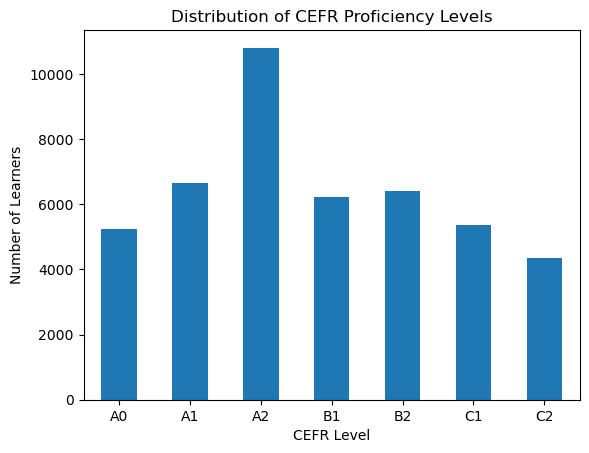

In [21]:

import matplotlib.pyplot as plt

df["cefr_level"].value_counts().reindex(
    ["A0", "A1", "A2", "B1", "B2", "C1", "C2"]
).plot(kind="bar")

plt.title("Distribution of CEFR Proficiency Levels")
plt.xlabel("CEFR Level")
plt.ylabel("Number of Learners")
plt.xticks(rotation=0)
plt.show()


In [22]:

# Expected fluency label based on CEFR level
df["expected_fluency"] = df["cefr_level"].isin(
    ["B2", "C1", "C2"]
).astype(int)

# Compare expected labels with the actual target
comparison = pd.crosstab(
    df["cefr_level"],
    df["reached_fluency"],
    rownames=["CEFR Level"],
    colnames=["Actual Fluency Label"]
)

print("CEFR level vs actual fluency label:")
display(comparison)

# Count inconsistencies
mismatches = (
    df["expected_fluency"] != df["reached_fluency"]
).sum()

print("Number of inconsistent records:", mismatches)


CEFR level vs actual fluency label:


Actual Fluency Label,0,1
CEFR Level,,
A0,5230,0
A1,6657,0
A2,10800,0
B1,6220,0
B2,0,6389
C1,0,5360
C2,0,4344


Number of inconsistent records: 0


In [23]:

dropout_comparison = pd.crosstab(
    df["cefr_level"],
    df["dropped_out"],
    rownames=["CEFR Level"],
    colnames=["Dropped Out"]
)

display(dropout_comparison)

print("\nDropout rate by CEFR level (%):")
print(
    (df.groupby("cefr_level")["dropped_out"].mean() * 100)
    .reindex(["A0", "A1", "A2", "B1", "B2", "C1", "C2"])
    .round(2)
)


Dropped Out,0,1
CEFR Level,,
A0,2031,3199
A1,2668,3989
A2,4636,6164
B1,2892,3328
B2,6389,0
C1,5360,0
C2,4344,0



Dropout rate by CEFR level (%):
cefr_level
A0    61.17
A1    59.92
A2    57.07
B1    53.50
B2     0.00
C1     0.00
C2     0.00
Name: dropped_out, dtype: float64


In [24]:

print("Study hours summary:")
display(df["total_study_hours"].describe())

print("\nAccent score summary:")
display(df["accent_nativelike"].describe())


Study hours summary:


count    45000.000000
mean       575.624667
std        429.467155
min         10.000000
25%        260.000000
50%        470.000000
75%        780.000000
max       4320.000000
Name: total_study_hours, dtype: float64


Accent score summary:


count    45000.000000
mean         5.702435
std          1.963940
min          0.000000
25%          4.370000
50%          5.720000
75%          7.060000
max         10.000000
Name: accent_nativelike, dtype: float64

In [25]:

print("Study hours:")
print("Minimum:", df["total_study_hours"].min())
print("Maximum:", df["total_study_hours"].max())
print("Zero or negative values:", (df["total_study_hours"] <= 0).sum())

print("\nAccent score:")
print("Minimum:", df["accent_nativelike"].min())
print("Maximum:", df["accent_nativelike"].max())
print("Outside 0-10 range:", (
    (df["accent_nativelike"] < 0) |
    (df["accent_nativelike"] > 10)
).sum())


Study hours:
Minimum: 10
Maximum: 4320
Zero or negative values: 0

Accent score:
Minimum: 0.0
Maximum: 10.0
Outside 0-10 range: 0


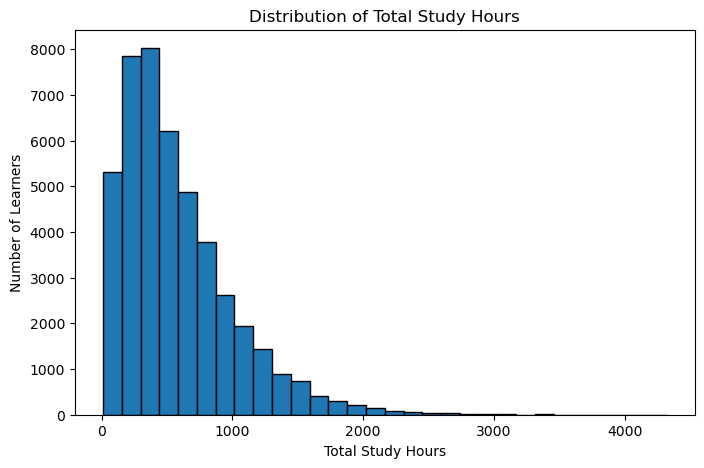

In [26]:
plt.figure(figsize=(8, 5))

plt.hist(df["total_study_hours"], bins=30, edgecolor="black")

plt.title("Distribution of Total Study Hours")
plt.xlabel("Total Study Hours")
plt.ylabel("Number of Learners")

plt.show()

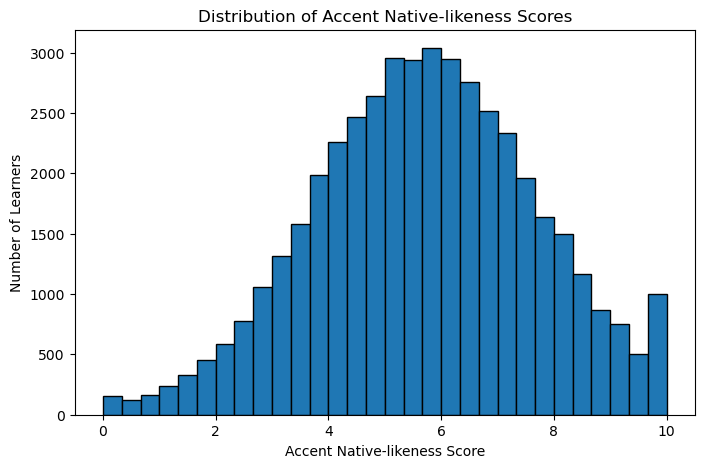

In [27]:

plt.figure(figsize=(8, 5))

plt.hist(df["accent_nativelike"], bins=30, edgecolor="black")

plt.title("Distribution of Accent Native-likeness Scores")
plt.xlabel("Accent Native-likeness Score")
plt.ylabel("Number of Learners")

plt.show()


In [28]:

regression_columns = [
    "age_started",
    "fsi_category",
    "prior_languages",
    "total_study_hours",
    "active_use_share",
    "immersion_months",
    "speaking_practice",
    "feedback_quality",
    "comprehensible_input_hours",
    "uses_srs",
    "motivation",
    "consistency",
    "accent_nativelike"
]

correlation = df[regression_columns].corr()

print("Correlation with total study hours:")
display(
    correlation["total_study_hours"]
    .sort_values(ascending=False)
)

print("Correlation with accent native-likeness:")
display(
    correlation["accent_nativelike"]
    .sort_values(ascending=False)
)


Correlation with total study hours:


total_study_hours             1.000000
comprehensible_input_hours    0.914930
age_started                   0.008628
immersion_months              0.006839
uses_srs                      0.003104
prior_languages               0.000495
consistency                   0.000269
fsi_category                 -0.000803
motivation                   -0.000864
active_use_share             -0.004350
accent_nativelike            -0.006931
feedback_quality             -0.010484
speaking_practice            -0.010614
Name: total_study_hours, dtype: float64

Correlation with accent native-likeness:


accent_nativelike             1.000000
immersion_months              0.061879
feedback_quality              0.008154
uses_srs                      0.005040
consistency                   0.004233
fsi_category                  0.004232
motivation                    0.003557
active_use_share             -0.000498
prior_languages              -0.002789
speaking_practice            -0.005187
comprehensible_input_hours   -0.006234
total_study_hours            -0.006931
age_started                  -0.652900
Name: accent_nativelike, dtype: float64

In [29]:

print("Correlation with accent native-likeness:")
display(
    correlation["accent_nativelike"]
    .sort_values(ascending=False)
)


Correlation with accent native-likeness:


accent_nativelike             1.000000
immersion_months              0.061879
feedback_quality              0.008154
uses_srs                      0.005040
consistency                   0.004233
fsi_category                  0.004232
motivation                    0.003557
active_use_share             -0.000498
prior_languages              -0.002789
speaking_practice            -0.005187
comprehensible_input_hours   -0.006234
total_study_hours            -0.006931
age_started                  -0.652900
Name: accent_nativelike, dtype: float64

In [30]:

columns_to_check = [
    "total_study_hours",
    "comprehensible_input_hours",
    "age_started",
    "accent_nativelike",
    "immersion_months"
]

display(
    data_dictionary[
        data_dictionary["column"].isin(columns_to_check)
    ].reset_index(drop=True)
)


,column,type,description
0,age_started,int,Age when the learner started (affects accent c...
1,total_study_hours,int,Total study hours (the biggest single lever)
2,immersion_months,float,QUALITY: months living/using the language imme...
3,comprehensible_input_hours,int,Hours of comprehensible input (listening/reading)
4,accent_nativelike,float,How native-like the accent is (0-10) — age-sen...


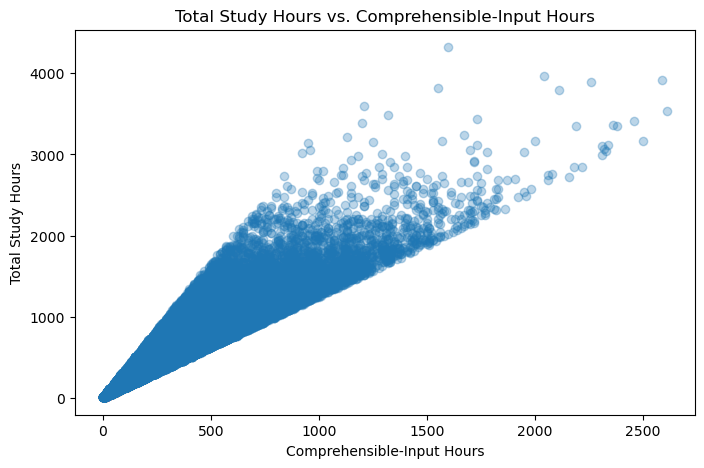

In [31]:

plt.figure(figsize=(8, 5))

plt.scatter(
    df["comprehensible_input_hours"],
    df["total_study_hours"],
    alpha=0.3
)

plt.title("Total Study Hours vs. Comprehensible-Input Hours")
plt.xlabel("Comprehensible-Input Hours")
plt.ylabel("Total Study Hours")

plt.show()


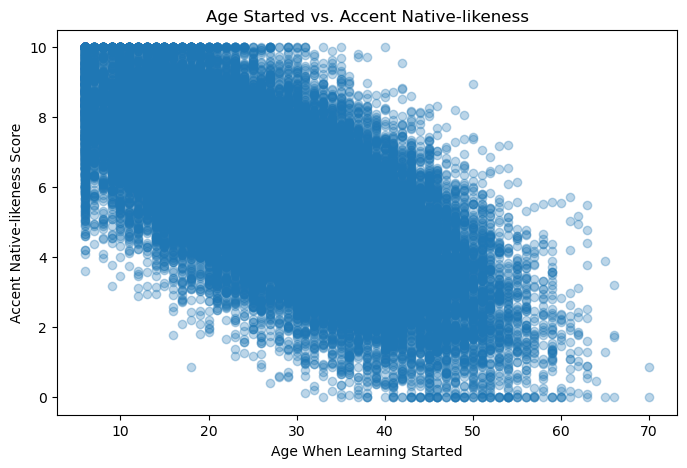

In [32]:

plt.figure(figsize=(8, 5))

plt.scatter(
    df["age_started"],
    df["accent_nativelike"],
    alpha=0.3
)

plt.title("Age Started vs. Accent Native-likeness")
plt.xlabel("Age When Learning Started")
plt.ylabel("Accent Native-likeness Score")

plt.show()


In [36]:

features_to_compare = [
    "age_started",
    "fsi_category",
    "prior_languages",
    "total_study_hours",
    "active_use_share",
    "immersion_months",
    "speaking_practice",
    "feedback_quality",
    "comprehensible_input_hours",
    "uses_srs",
    "motivation",
    "consistency",
    "accent_nativelike"
]

fluency_comparison = df.groupby("reached_fluency")[
    features_to_compare
].mean().T

fluency_comparison.columns = [
    "Did not reach B2+",
    "Reached B2+"
]

fluency_comparison["Difference"] = (
    fluency_comparison["Reached B2+"] -
    fluency_comparison["Did not reach B2+"]
)

display(fluency_comparison.round(2))


,Did not reach B2+,Reached B2+,Difference
age_started,28.03,28.16,0.12
fsi_category,2.61,1.79,-0.82
prior_languages,0.79,0.83,0.04
total_study_hours,399.71,891.61,491.90
active_use_share,0.36,0.48,0.12
immersion_months,1.16,1.93,0.77
speaking_practice,5.96,6.43,0.47
feedback_quality,4.89,5.19,0.30
comprehensible_input_hours,219.93,490.61,270.67
uses_srs,0.40,0.42,0.02


In [37]:

dropout_comparison = df.groupby("dropped_out")[
    features_to_compare
].mean().T

dropout_comparison.columns = [
    "Did not drop out",
    "Dropped out"
]

dropout_comparison["Difference"] = (
    dropout_comparison["Dropped out"] -
    dropout_comparison["Did not drop out"]
)

display(dropout_comparison.round(2))


,Did not drop out,Dropped out,Difference
age_started,28.07,28.10,0.03
fsi_category,2.08,2.72,0.64
prior_languages,0.80,0.80,-0.01
total_study_hours,671.90,412.16,-259.74
active_use_share,0.43,0.35,-0.08
immersion_months,1.72,0.95,-0.77
speaking_practice,6.24,5.94,-0.30
feedback_quality,5.06,4.89,-0.17
comprehensible_input_hours,370.20,225.95,-144.26
uses_srs,0.41,0.40,-0.01


In [38]:

cefr_comparison = df.groupby("cefr_level")[
    features_to_compare
].mean()

cefr_comparison = cefr_comparison.reindex(
    ["A0", "A1", "A2", "B1", "B2", "C1", "C2"]
)

display(cefr_comparison.round(2))


,age_started,fsi_category,prior_languages,total_study_hours,active_use_share,immersion_months,speaking_practice,feedback_quality,comprehensible_input_hours,uses_srs,motivation,consistency,accent_nativelike
cefr_level,,,,,,,,,,,,,
A0,28.13,3.03,0.77,157.23,0.30,0.93,5.70,4.74,87.19,0.39,5.02,6.43,5.67
A1,27.98,2.81,0.78,308.41,0.33,1.04,5.89,4.86,169.50,0.39,5.01,6.45,5.69
A2,27.97,2.52,0.79,461.36,0.37,1.21,6.03,4.95,254.12,0.40,4.95,6.45,5.72
B1,28.12,2.22,0.80,594.28,0.41,1.40,6.12,4.96,326.17,0.41,4.99,6.40,5.70
B2,28.23,2.00,0.82,712.17,0.44,1.53,6.26,5.10,391.31,0.41,5.00,6.40,5.70
C1,28.10,1.79,0.81,876.57,0.47,1.81,6.45,5.15,485.29,0.41,5.02,6.46,5.70
C2,28.11,1.49,0.86,1174.07,0.54,2.65,6.64,5.37,643.21,0.42,4.99,6.49,5.74
